In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Project folders
BASE_DIR = Path.cwd()

# Handle both project-folder and notebooks-folder working directories
if BASE_DIR.name.lower() == "notebooks":
    BASE_DIR = BASE_DIR.parent

REPORTS_DIR = BASE_DIR / "reports"
MODELS_DIR = BASE_DIR / "models"

# Create folders if they do not exist
REPORTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

print("FraudShield AI - Credit Card Fraud Detection")
print("Libraries imported successfully!")
print("Reports and Models folders are ready!")


FraudShield AI - Credit Card Fraud Detection
Libraries imported successfully!
Reports and Models folders are ready!


In [6]:
# Load the credit card dataset

df = pd.read_csv("../dataset/creditcard.csv")

# Display the first 5 rows
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [7]:
# Check dataset dimensions
print("Dataset Shape:", df.shape)

# Check column names
print("\nColumn Names:")
print(df.columns.tolist())

# Check data types and missing values
print("\nDataset Information:")
df.info()

Dataset Shape: (284807, 31)

Column Names:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14    

In [8]:
# Check dataset dimensions
print("Dataset Shape:", df.shape)

# Check column names
print("\nColumn Names:")
print(df.columns.tolist())

# Check data types and missing values
print("\nDataset Information:")
df.info()

Dataset Shape: (284807, 31)

Column Names:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14    

In [9]:
# Count genuine and fraudulent transactions

class_counts = df['Class'].value_counts()

print("Transaction Distribution:")
print("Genuine Transactions (0):", class_counts[0])
print("Fraudulent Transactions (1):", class_counts[1])

print("\nPercentage Distribution:")
print((df['Class'].value_counts(normalize=True) * 100).round(4))

Transaction Distribution:
Genuine Transactions (0): 284315
Fraudulent Transactions (1): 492

Percentage Distribution:
Class
0    99.8273
1     0.1727
Name: proportion, dtype: float64


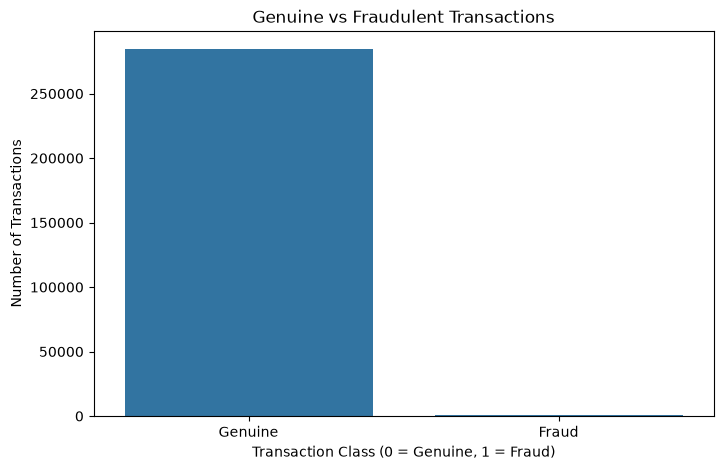

In [10]:
# Visualize transaction distribution

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='Class'
)

plt.title('Genuine vs Fraudulent Transactions')
plt.xlabel('Transaction Class (0 = Genuine, 1 = Fraud)')
plt.ylabel('Number of Transactions')

plt.xticks([0, 1], ['Genuine', 'Fraud'])

plt.show()

In [11]:
# Statistical analysis of transaction amounts

print("Transaction Amount Statistics:")
print(df['Amount'].describe())

print("\nAverage Amount by Transaction Class:")
print(df.groupby('Class')['Amount'].mean())

Transaction Amount Statistics:
count    284807.000000
mean         88.349619
std         250.120109
min           0.000000
25%           5.600000
50%          22.000000
75%          77.165000
max       25691.160000
Name: Amount, dtype: float64

Average Amount by Transaction Class:
Class
0     88.291022
1    122.211321
Name: Amount, dtype: float64


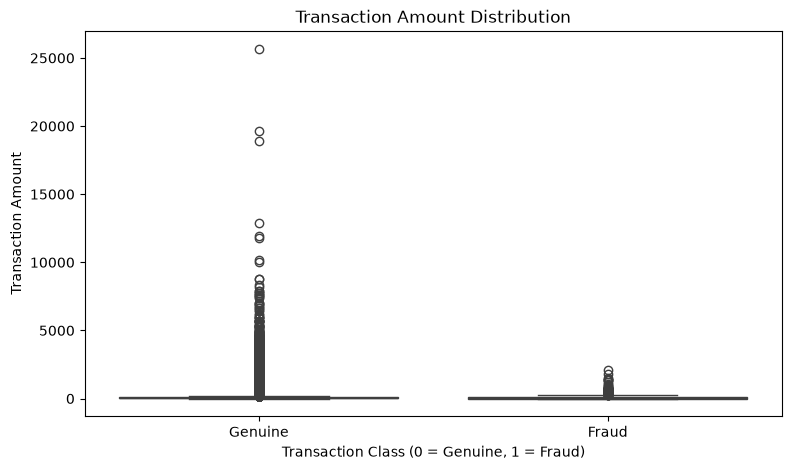

In [12]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x='Class',
    y='Amount'
)

plt.title('Transaction Amount Distribution')
plt.xlabel('Transaction Class (0 = Genuine, 1 = Fraud)')
plt.ylabel('Transaction Amount')

plt.xticks([0, 1], ['Genuine', 'Fraud'])

plt.show()

In [13]:
# Check duplicate transactions

duplicate_count = df.duplicated().sum()

print("Total Duplicate Rows:", duplicate_count)

if duplicate_count == 0:
    print("No duplicate transactions found.")
else:
    print("Duplicate transactions are present.")

Total Duplicate Rows: 1081
Duplicate transactions are present.


In [14]:
# Remove duplicate transactions

df = df.drop_duplicates()

# Check dataset after removing duplicates

print("Dataset shape after removing duplicates:", df.shape)

print("Remaining duplicate rows:", df.duplicated().sum())

Dataset shape after removing duplicates: (283726, 31)
Remaining duplicate rows: 0


In [15]:
# Check class distribution after cleaning

print("Cleaned Dataset Shape:", df.shape)

print("\nTransaction Distribution:")
print(df['Class'].value_counts())

print("\nFraud Percentage:")
print(round(df['Class'].mean() * 100, 4), "%")

Cleaned Dataset Shape: (283726, 31)

Transaction Distribution:
Class
0    283253
1       473
Name: count, dtype: int64

Fraud Percentage:
0.1667 %


In [16]:
# Separate features and target

X = df.drop('Class', axis=1)

y = df['Class']

print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nInput Features:")
print(X.columns.tolist())

Input Features Shape: (283726, 30)
Target Shape: (283726,)

Input Features:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount']


In [17]:
# Split dataset into training and testing sets

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target:", y_train.shape)
print("Testing Target:", y_test.shape)

print("\nFraud cases in training data:", sum(y_train))
print("Fraud cases in testing data:", sum(y_test))

Training Features: (226980, 30)
Testing Features: (56746, 30)

Training Target: (226980,)
Testing Target: (56746,)

Fraud cases in training data: 378
Fraud cases in testing data: 95


In [18]:
# Handle class imbalance using SMOTE

from imblearn.over_sampling import SMOTE

print("Before SMOTE:")
print(y_train.value_counts())

smote = SMOTE(
    random_state=42,
    sampling_strategy='auto'
)

X_train_resampled, y_train_resampled = smote.fit_resample(
    X_train,
    y_train
)

print("\nAfter SMOTE:")
print(y_train_resampled.value_counts())

print("\nResampled Training Shape:", X_train_resampled.shape)

Before SMOTE:
Class
0    226602
1       378
Name: count, dtype: int64

After SMOTE:
Class
0    226602
1    226602
Name: count, dtype: int64

Resampled Training Shape: (453204, 30)


In [19]:
# Train Logistic Regression model

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Create model
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train model
lr_model.fit(X_train_resampled, y_train_resampled)

print("Logistic Regression Model Trained Successfully!")

Logistic Regression Model Trained Successfully!


C:\Users\BHAVANA H M\AppData\Roaming\Python\Python314\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [20]:
# Scale features for Logistic Regression

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Create scaler
scaler = StandardScaler()

# Fit only on training data
X_train_scaled = scaler.fit_transform(X_train_resampled)

# Transform testing data using the same scaler
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully!")

Feature scaling completed successfully!


In [21]:
# Train Logistic Regression with scaled data

lr_model = LogisticRegression(
    max_iter=3000,
    random_state=42,
    solver='lbfgs'
)

lr_model.fit(X_train_scaled, y_train_resampled)

print("Logistic Regression Model Trained Successfully!")

Logistic Regression Model Trained Successfully!


In [22]:
# Evaluate Logistic Regression Model

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

# Make predictions
y_pred_lr = lr_model.predict(X_test_scaled)

# Get fraud probabilities
y_prob_lr = lr_model.predict_proba(X_test_scaled)[:, 1]

# Classification report
print("LOGISTIC REGRESSION - MODEL EVALUATION")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr, digits=4))

# Confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

# ROC-AUC score
print("\nROC-AUC Score:")
print(roc_auc_score(y_test, y_prob_lr))

# Precision-Recall AUC
print("\nPR-AUC Score:")
print(average_precision_score(y_test, y_prob_lr))

LOGISTIC REGRESSION - MODEL EVALUATION

Classification Report:
              precision    recall  f1-score   support

           0     0.9998    0.9914    0.9956     56651
           1     0.1424    0.8526    0.2440        95

    accuracy                         0.9912     56746
   macro avg     0.5711    0.9220    0.6198     56746
weighted avg     0.9983    0.9912    0.9943     56746


Confusion Matrix:
[[56163   488]
 [   14    81]]

ROC-AUC Score:
0.9629093740157882

PR-AUC Score:
0.7027249941620092


In [23]:
# Store Logistic Regression results

lr_results = {
    "Model": "Logistic Regression",
    "Precision": 0.1424,
    "Recall": 0.8526,
    "F1 Score": 0.2440,
    "ROC-AUC": 0.9629,
    "PR-AUC": 0.7027
}

print("Logistic Regression Results Saved!")
print(lr_results)

Logistic Regression Results Saved!
{'Model': 'Logistic Regression', 'Precision': 0.1424, 'Recall': 0.8526, 'F1 Score': 0.244, 'ROC-AUC': 0.9629, 'PR-AUC': 0.7027}


In [24]:
# Import Random Forest Classifier

from sklearn.ensemble import RandomForestClassifier

print("Random Forest imported successfully!")

Random Forest imported successfully!


In [25]:
# Train Random Forest Classifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=None,
    min_samples_split=2,
    random_state=42,
    n_jobs=-1,
    class_weight=None
)

rf_model.fit(X_train_resampled, y_train_resampled)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


In [26]:
# Evaluate Random Forest Model

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

# Make predictions
y_pred_rf = rf_model.predict(X_test)

# Get fraud probabilities
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

# Classification report
print("RANDOM FOREST - MODEL EVALUATION")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf, digits=4))

# Confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

# ROC-AUC score
print("\nROC-AUC Score:")
print(roc_auc_score(y_test, y_prob_rf))

# Precision-Recall AUC
print("\nPR-AUC Score:")
print(average_precision_score(y_test, y_prob_rf))

RANDOM FOREST - MODEL EVALUATION

Classification Report:
              precision    recall  f1-score   support

           0     0.9996    0.9998    0.9997     56651
           1     0.8902    0.7684    0.8249        95

    accuracy                         0.9995     56746
   macro avg     0.9449    0.8841    0.9123     56746
weighted avg     0.9994    0.9995    0.9994     56746


Confusion Matrix:
[[56642     9]
 [   22    73]]

ROC-AUC Score:
0.9608973316771479

PR-AUC Score:
0.8042848835599401


In [27]:
# Store Random Forest results

rf_results = {
    "Model": "Random Forest",
    "Precision": 0.8902,
    "Recall": 0.7684,
    "F1 Score": 0.8249,
    "ROC-AUC": 0.9609,
    "PR-AUC": 0.8043
}

print("Random Forest Results Saved!")
print(rf_results)


Random Forest Results Saved!
{'Model': 'Random Forest', 'Precision': 0.8902, 'Recall': 0.7684, 'F1 Score': 0.8249, 'ROC-AUC': 0.9609, 'PR-AUC': 0.8043}


In [28]:
# Import Decision Tree Classifier

from sklearn.tree import DecisionTreeClassifier

print("Decision Tree imported successfully!")

Decision Tree imported successfully!


In [29]:
# Train Decision Tree Classifier

dt_model = DecisionTreeClassifier(
    criterion='gini',
    max_depth=15,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42,
    class_weight=None
)

dt_model.fit(X_train_resampled, y_train_resampled)

print("Decision Tree Model Trained Successfully!")

Decision Tree Model Trained Successfully!


In [30]:
# Evaluate Decision Tree Model

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

# Make predictions
y_pred_dt = dt_model.predict(X_test)

# Get fraud probabilities
y_prob_dt = dt_model.predict_proba(X_test)[:, 1]

# Classification report
print("DECISION TREE - MODEL EVALUATION")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt, digits=4))

# Confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_dt))

# ROC-AUC score
print("\nROC-AUC Score:")
print(roc_auc_score(y_test, y_prob_dt))

# Precision-Recall AUC
print("\nPR-AUC Score:")
print(average_precision_score(y_test, y_prob_dt))

DECISION TREE - MODEL EVALUATION

Classification Report:
              precision    recall  f1-score   support

           0     0.9996    0.9959    0.9978     56651
           1     0.2451    0.7895    0.3741        95

    accuracy                         0.9956     56746
   macro avg     0.6224    0.8927    0.6859     56746
weighted avg     0.9984    0.9956    0.9967     56746


Confusion Matrix:
[[56420   231]
 [   20    75]]

ROC-AUC Score:
0.8935772026136017

PR-AUC Score:
0.4442692704005296


In [31]:
# Store Decision Tree results

dt_results = {
    "Model": "Decision Tree",
    "Precision": 0.2451,
    "Recall": 0.7895,
    "F1 Score": 0.3741,
    "ROC-AUC": 0.8936,
    "PR-AUC": 0.4443
}

print("Decision Tree Results Saved!")
print(dt_results)

Decision Tree Results Saved!
{'Model': 'Decision Tree', 'Precision': 0.2451, 'Recall': 0.7895, 'F1 Score': 0.3741, 'ROC-AUC': 0.8936, 'PR-AUC': 0.4443}


In [32]:
# Import XGBoost Classifier

from xgboost import XGBClassifier

print("XGBoost imported successfully!")

XGBoost imported successfully!


In [33]:
# Train XGBoost Classifier

xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='binary:logistic',
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train_resampled, y_train_resampled)

print("XGBoost Model Trained Successfully!")

XGBoost Model Trained Successfully!


In [34]:
# Evaluate XGBoost Model

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

# Make predictions
y_pred_xgb = xgb_model.predict(X_test)

# Get fraud probabilities
y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

# Classification report
print("XGBOOST - MODEL EVALUATION")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_xgb, digits=4))

# Confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_xgb))

# ROC-AUC score
print("\nROC-AUC Score:")
print(roc_auc_score(y_test, y_prob_xgb))

# Precision-Recall AUC
print("\nPR-AUC Score:")
print(average_precision_score(y_test, y_prob_xgb))

XGBOOST - MODEL EVALUATION

Classification Report:
              precision    recall  f1-score   support

           0     0.9997    0.9990    0.9994     56651
           1     0.5878    0.8105    0.6814        95

    accuracy                         0.9987     56746
   macro avg     0.7937    0.9048    0.8404     56746
weighted avg     0.9990    0.9987    0.9988     56746


Confusion Matrix:
[[56597    54]
 [   18    77]]

ROC-AUC Score:
0.9701368211087461

PR-AUC Score:
0.8003762312027766


In [35]:
# Store XGBoost results

xgb_results = {
    "Model": "XGBoost",
    "Precision": 0.5878,
    "Recall": 0.8105,
    "F1 Score": 0.6814,
    "ROC-AUC": 0.9701,
    "PR-AUC": 0.8004
}

print("XGBoost Results Saved!")
print(xgb_results)

XGBoost Results Saved!
{'Model': 'XGBoost', 'Precision': 0.5878, 'Recall': 0.8105, 'F1 Score': 0.6814, 'ROC-AUC': 0.9701, 'PR-AUC': 0.8004}


In [37]:
# Import Isolation Forest

from sklearn.ensemble import IsolationForest

print("Isolation Forest imported successfully!")

Isolation Forest imported successfully!


In [38]:
# Train Isolation Forest Model

iso_model = IsolationForest(
    n_estimators=100,
    contamination=0.001667,
    max_samples='auto',
    random_state=42,
    n_jobs=-1
)

# Select only genuine transactions for training
X_train_genuine = X_train[y_train == 0]

# Train the model
iso_model.fit(X_train_genuine)

print("Isolation Forest Model Trained Successfully!")

Isolation Forest Model Trained Successfully!


In [39]:
# Evaluate Isolation Forest Model

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

# Predict on test data
# Isolation Forest: 1 = Normal, -1 = Anomaly
iso_predictions = iso_model.predict(X_test)

# Convert predictions: 0 = Genuine, 1 = Fraud
y_pred_iso = (iso_predictions == -1).astype(int)

# Anomaly scores: lower decision scores indicate more unusual transactions
y_score_iso = -iso_model.decision_function(X_test)

# Classification report
print("ISOLATION FOREST - MODEL EVALUATION")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_iso, digits=4))

# Confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_iso))

# ROC-AUC
print("\nROC-AUC Score:")
print(roc_auc_score(y_test, y_score_iso))

# Precision-Recall AUC
print("\nPR-AUC Score:")
print(average_precision_score(y_test, y_score_iso))

ISOLATION FOREST - MODEL EVALUATION

Classification Report:
              precision    recall  f1-score   support

           0     0.9986    0.9981    0.9983     56651
           1     0.1280    0.1684    0.1455        95

    accuracy                         0.9967     56746
   macro avg     0.5633    0.5832    0.5719     56746
weighted avg     0.9971    0.9967    0.9969     56746


Confusion Matrix:
[[56542   109]
 [   79    16]]

ROC-AUC Score:
0.9292718389325593

PR-AUC Score:
0.0703731495795467


In [40]:
# Store Isolation Forest results

iso_results = {
    "Model": "Isolation Forest",
    "Precision": 0.1280,
    "Recall": 0.1684,
    "F1 Score": 0.1455,
    "ROC-AUC": 0.9293,
    "PR-AUC": 0.0704
}

print("Isolation Forest Results Saved!")
print(iso_results)

Isolation Forest Results Saved!
{'Model': 'Isolation Forest', 'Precision': 0.128, 'Recall': 0.1684, 'F1 Score': 0.1455, 'ROC-AUC': 0.9293, 'PR-AUC': 0.0704}


In [41]:
# Combine results of all five models

import pandas as pd

all_results = [
    lr_results,
    rf_results,
    dt_results,
    xgb_results,
    iso_results
]

results_df = pd.DataFrame(all_results)

# Sort models by F1 Score
results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

print("FIVE MODEL COMPARISON")
display(results_df)

FIVE MODEL COMPARISON


,Model,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Random Forest,0.8902,0.7684,0.8249,0.9609,0.8043
1,XGBoost,0.5878,0.8105,0.6814,0.9701,0.8004
2,Decision Tree,0.2451,0.7895,0.3741,0.8936,0.4443
3,Logistic Regression,0.1424,0.8526,0.2440,0.9629,0.7027
4,Isolation Forest,0.1280,0.1684,0.1455,0.9293,0.0704


In [42]:
# Display clean comparison table

results_df = pd.DataFrame(all_results)

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

display(
    results_df.style.format({
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}",
        "ROC-AUC": "{:.4f}",
        "PR-AUC": "{:.4f}"
    }).hide(axis="index")
)

Model,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
Random Forest,0.8902,0.7684,0.8249,0.9609,0.8043
XGBoost,0.5878,0.8105,0.6814,0.9701,0.8004
Decision Tree,0.2451,0.7895,0.3741,0.8936,0.4443
Logistic Regression,0.1424,0.8526,0.2440,0.9629,0.7027
Isolation Forest,0.1280,0.1684,0.1455,0.9293,0.0704


In [43]:
# Correct Isolation Forest results

iso_results = {
    "Model": "Isolation Forest",
    "Precision": 0.1280,
    "Recall": 0.1684,
    "F1 Score": 0.1455,
    "ROC-AUC": 0.9293,
    "PR-AUC": 0.0704
}

print("Isolation Forest results corrected!")

Isolation Forest results corrected!


In [44]:
all_results = [
    lr_results,
    rf_results,
    dt_results,
    xgb_results,
    iso_results
]

results_df = pd.DataFrame(all_results)

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

display(results_df)

,Model,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Random Forest,0.8902,0.7684,0.8249,0.9609,0.8043
1,XGBoost,0.5878,0.8105,0.6814,0.9701,0.8004
2,Decision Tree,0.2451,0.7895,0.3741,0.8936,0.4443
3,Logistic Regression,0.1424,0.8526,0.2440,0.9629,0.7027
4,Isolation Forest,0.1280,0.1684,0.1455,0.9293,0.0704


In [45]:
results_df.to_csv(
    "E:/Credit_Card_Fraud_Detection/reports/model_comparison.csv",
    index=False
)

print("Model comparison saved successfully!")

Model comparison saved successfully!


In [46]:
import os

os.makedirs(
    "E:/Credit_Card_Fraud_Detection/reports",
    exist_ok=True
)

print("Reports folder created successfully!")

Reports folder created successfully!


In [47]:
results_df.to_csv(
    "E:/Credit_Card_Fraud_Detection/reports/model_comparison.csv",
    index=False
)

print("Model comparison saved successfully!")

Model comparison saved successfully!


In [48]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

print("Visualization libraries imported successfully!")

Visualization libraries imported successfully!


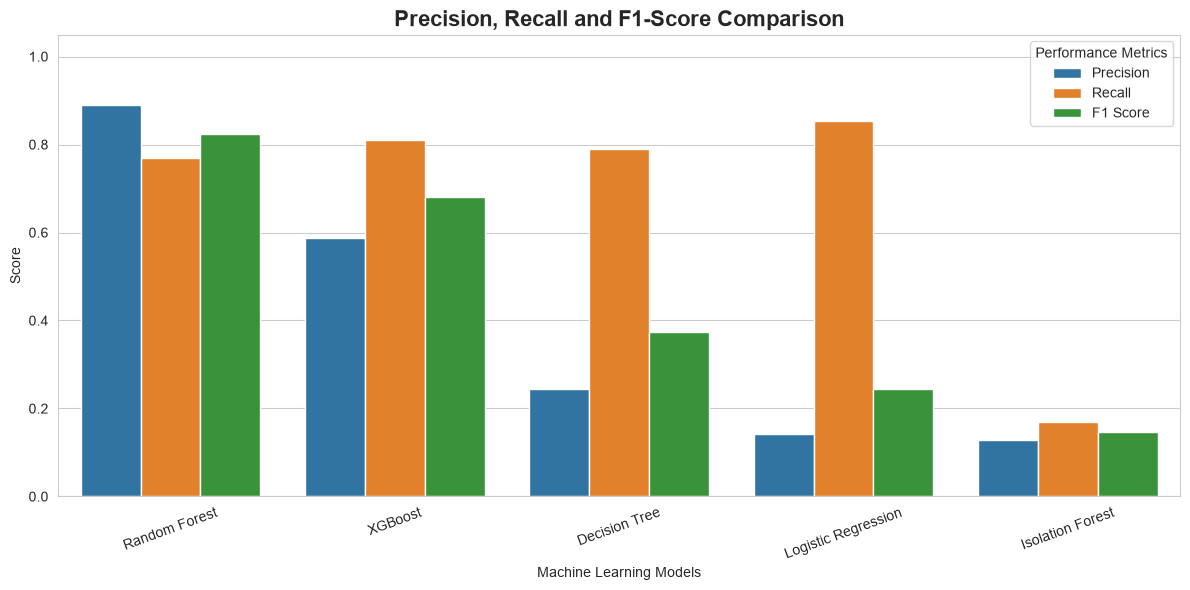

In [49]:
# Model Performance Comparison

metrics = results_df.melt(
    id_vars="Model",
    value_vars=["Precision", "Recall", "F1 Score"],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=metrics,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title(
    "Precision, Recall and F1-Score Comparison",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Machine Learning Models")
plt.ylabel("Score")

plt.xticks(rotation=20)
plt.ylim(0, 1.05)

plt.legend(title="Performance Metrics")
plt.tight_layout()

plt.savefig(
    "E:/Credit_Card_Fraud_Detection/reports/model_metrics_comparison.png",
    dpi=300
)

plt.show()

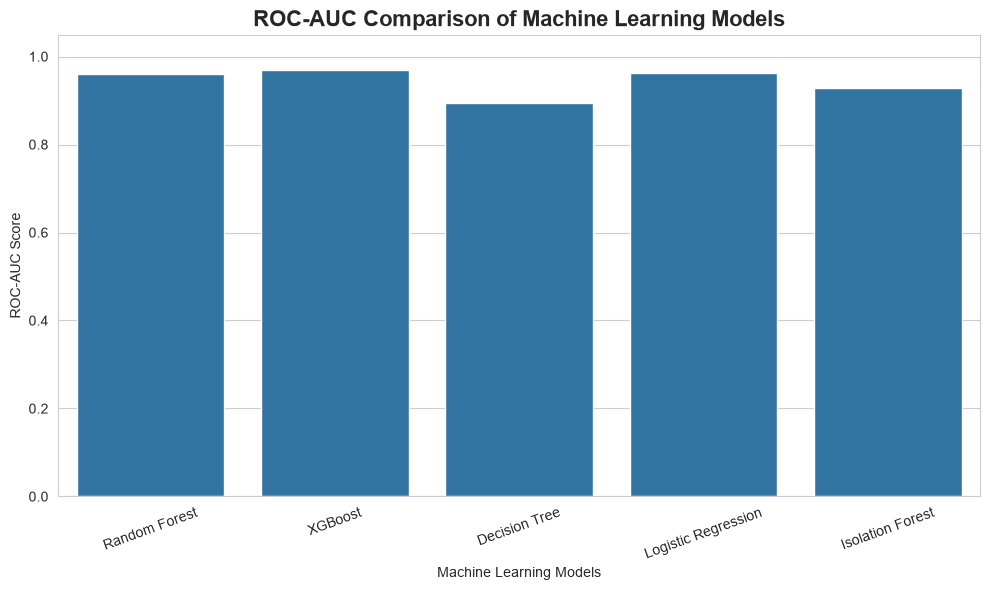

In [50]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="ROC-AUC"
)

plt.title(
    "ROC-AUC Comparison of Machine Learning Models",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Machine Learning Models")
plt.ylabel("ROC-AUC Score")

plt.xticks(rotation=20)
plt.ylim(0, 1.05)

plt.tight_layout()

plt.savefig(
    "E:/Credit_Card_Fraud_Detection/reports/roc_auc_comparison.png",
    dpi=300
)

plt.show()

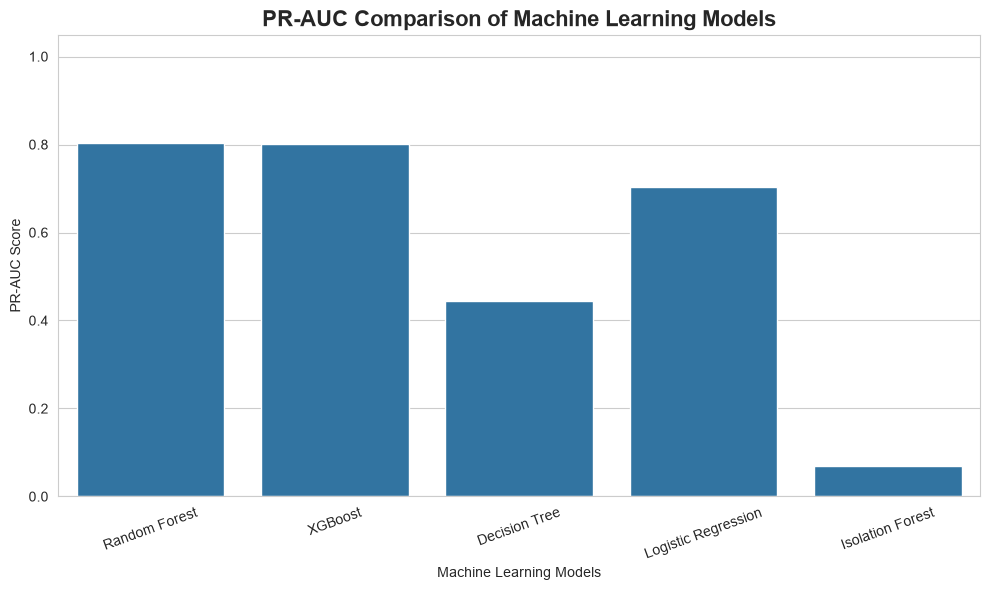

In [51]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="PR-AUC"
)

plt.title(
    "PR-AUC Comparison of Machine Learning Models",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Machine Learning Models")
plt.ylabel("PR-AUC Score")

plt.xticks(rotation=20)
plt.ylim(0, 1.05)

plt.tight_layout()

plt.savefig(
    "E:/Credit_Card_Fraud_Detection/reports/pr_auc_comparison.png",
    dpi=300
)

plt.show()

In [52]:
# Check Random Forest prediction probabilities

print("First 10 prediction probabilities:")

print(y_prob_rf[:10])

print("\nDefault classification threshold: 0.50")

print("\nCurrent Random Forest performance:")
print(rf_results)

First 10 prediction probabilities:
[0.   0.   0.01 0.   0.   0.   0.   0.   0.   0.  ]

Default classification threshold: 0.50

Current Random Forest performance:
{'Model': 'Random Forest', 'Precision': 0.8902, 'Recall': 0.7684, 'F1 Score': 0.8249, 'ROC-AUC': 0.9609, 'PR-AUC': 0.8043}


In [53]:
from sklearn.model_selection import train_test_split

# Split original training data into training and validation sets

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Training data shape:", X_fit.shape)
print("Validation data shape:", X_val.shape)

print("\nFraud cases in validation data:")
print(y_val.value_counts())

Training data shape: (181584, 30)
Validation data shape: (45396, 30)

Fraud cases in validation data:
Class
0    45320
1       76
Name: count, dtype: int64


In [54]:
from imblearn.over_sampling import SMOTE

smote_val = SMOTE(
    random_state=42,
    sampling_strategy="auto"
)

X_fit_resampled, y_fit_resampled = smote_val.fit_resample(
    X_fit,
    y_fit
)

print("Before SMOTE:")
print(y_fit.value_counts())

print("\nAfter SMOTE:")
print(y_fit_resampled.value_counts())

print("\nResampled training shape:", X_fit_resampled.shape)

Before SMOTE:
Class
0    181282
1       302
Name: count, dtype: int64

After SMOTE:
Class
0    181282
1    181282
Name: count, dtype: int64

Resampled training shape: (362564, 30)


In [55]:
from sklearn.ensemble import RandomForestClassifier

rf_tuned_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=None,
    min_samples_split=2,
    random_state=42,
    n_jobs=-1
)

rf_tuned_model.fit(
    X_fit_resampled,
    y_fit_resampled
)

print("Random Forest validation model trained successfully!")

Random Forest validation model trained successfully!


In [56]:
# Predict fraud probabilities on validation data

y_prob_val = rf_tuned_model.predict_proba(X_val)[:, 1]

print("Validation predictions generated successfully!")

print("\nFirst 10 fraud probabilities:")
print(y_prob_val[:10])

print("\nTotal validation transactions:", len(y_prob_val))

Validation predictions generated successfully!

First 10 fraud probabilities:
[0.   0.   0.   0.   0.   0.   0.   0.   0.   0.02]

Total validation transactions: 45396


In [57]:
from sklearn.metrics import precision_score, recall_score, f1_score

threshold_results = []

thresholds = [0.10, 0.15, 0.20, 0.25, 0.30,
              0.35, 0.40, 0.45, 0.50, 0.55,
              0.60, 0.65, 0.70, 0.75, 0.80]

for threshold in thresholds:

    y_pred_val = (y_prob_val >= threshold).astype(int)

    precision = precision_score(y_val, y_pred_val, zero_division=0)
    recall = recall_score(y_val, y_pred_val, zero_division=0)
    f1 = f1_score(y_val, y_pred_val, zero_division=0)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

threshold_df = pd.DataFrame(threshold_results)

display(
    threshold_df.style.format({
        "Threshold": "{:.2f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}"
    })
)

,Threshold,Precision,Recall,F1 Score
0,0.10,0.3268,0.8816,0.4769
1,0.15,0.5410,0.8684,0.6667
2,0.20,0.6346,0.8684,0.7333
3,0.25,0.7333,0.8684,0.7952
4,0.30,0.8148,0.8684,0.8408
5,0.35,0.8684,0.8684,0.8684
6,0.40,0.9041,0.8684,0.8859
7,0.45,0.9155,0.8553,0.8844
8,0.50,0.9286,0.8553,0.8904
9,0.55,0.9286,0.8553,0.8904


In [58]:
best_threshold = 0.50

print("Selected threshold:", best_threshold)
print("Threshold saved successfully!")

Selected threshold: 0.5
Threshold saved successfully!


In [59]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

# Predict probabilities on untouched test data
y_prob_final = rf_tuned_model.predict_proba(X_test)[:, 1]

# Apply selected threshold
y_pred_final = (y_prob_final >= best_threshold).astype(int)

print("FINAL RANDOM FOREST MODEL PERFORMANCE")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_final))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_final))

print("\nFinal Precision:", precision_score(y_test, y_pred_final))
print("Final Recall:", recall_score(y_test, y_pred_final))
print("Final F1 Score:", f1_score(y_test, y_pred_final))

FINAL RANDOM FOREST MODEL PERFORMANCE

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.91      0.78      0.84        95

    accuracy                           1.00     56746
   macro avg       0.96      0.89      0.92     56746
weighted avg       1.00      1.00      1.00     56746


Confusion Matrix:
[[56644     7]
 [   21    74]]

Final Precision: 0.9135802469135802
Final Recall: 0.7789473684210526
Final F1 Score: 0.8409090909090909


In [60]:
import os
import joblib

# Create models folder
os.makedirs(
    "E:/Credit_Card_Fraud_Detection/models",
    exist_ok=True
)

# Save trained Random Forest model
joblib.dump(
    rf_tuned_model,
    "E:/Credit_Card_Fraud_Detection/models/random_forest_model.pkl"
)

# Save feature names
joblib.dump(
    list(X_train.columns),
    "E:/Credit_Card_Fraud_Detection/models/feature_columns.pkl"
)

# Save selected threshold
joblib.dump(
    best_threshold,
    "E:/Credit_Card_Fraud_Detection/models/best_threshold.pkl"
)

print("Final Random Forest model saved successfully!")
print("Feature columns saved successfully!")
print("Best threshold saved successfully!")

Final Random Forest model saved successfully!
Feature columns saved successfully!
Best threshold saved successfully!
